Project Name -
Flower Classification

Contribution - Individual
Member Name - DEVADHARSHINI M


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [2]:
#Load Iris Dataset
iris = load_iris()

X = pd.DataFrame(iris.data, columns=iris.feature_names)
y = pd.Series(iris.target, name="species")

df = X.copy()
df["species"] = y

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [3]:
#Species Name
df["species"] = df["species"].map({
    0: "setosa",
    1: "versicolor",
    2: "virginica"
})

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [4]:
#dataset info
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

Dataset Shape: (150, 5)

Column Names:
Index(['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)',
       'petal width (cm)', 'species'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [5]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [6]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64


In [7]:
#species distribution
print(df["species"].value_counts())

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


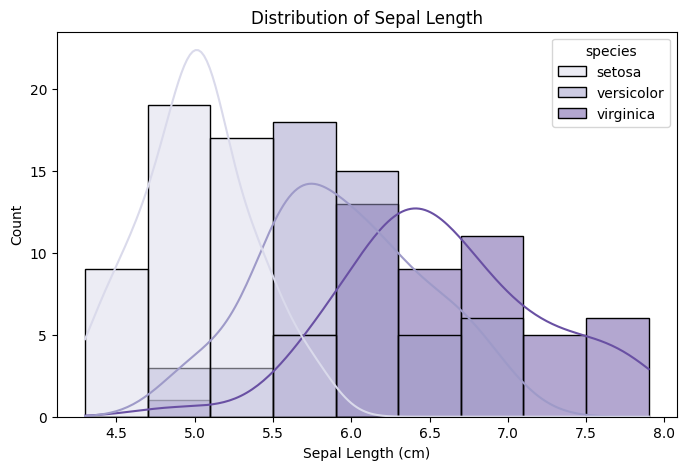

In [10]:
# sepal Length Distribution
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="sepal length (cm)",
    hue="species",
    kde=True,
    palette="Purples"
)

plt.title("Distribution of Sepal Length")
plt.xlabel("Sepal Length (cm)")
plt.ylabel("Count")
plt.show()

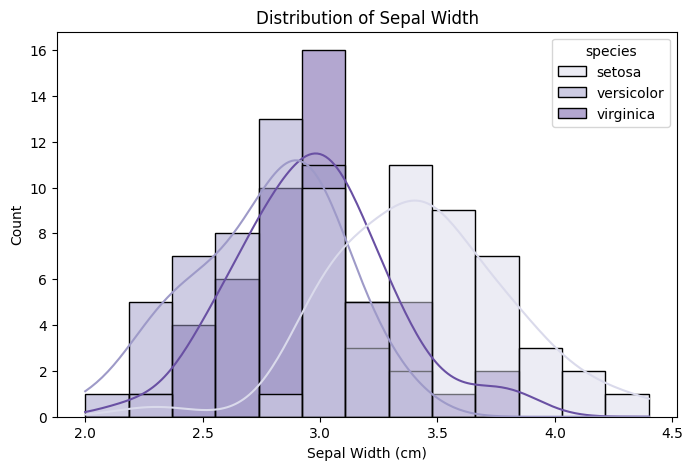

In [11]:
# sepal width
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="sepal width (cm)",
    hue="species",
    kde=True,
    palette="Purples"
)

plt.title("Distribution of Sepal Width")
plt.xlabel("Sepal Width (cm)")
plt.ylabel("Count")
plt.show()

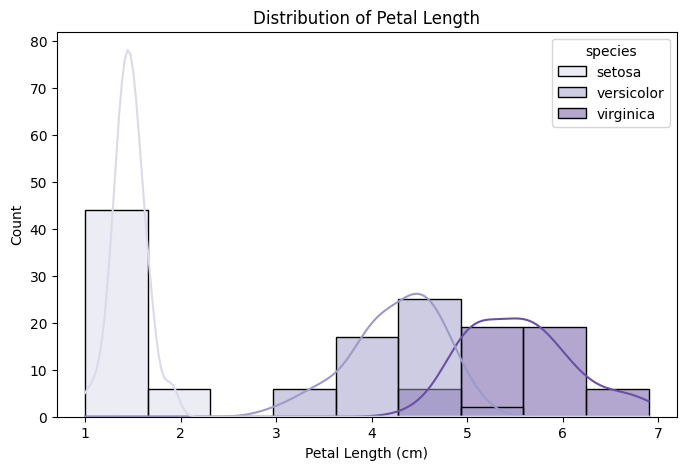

In [12]:
#petal length
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="petal length (cm)",
    hue="species",
    kde=True,
    palette="Purples"
)

plt.title("Distribution of Petal Length")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Count")
plt.show()

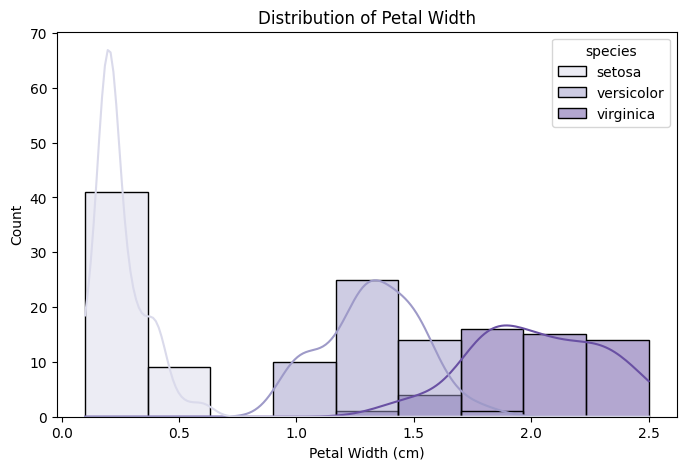

In [13]:
#petal width
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="petal width (cm)",
    hue="species",
    kde=True,
    palette="Purples"
)

plt.title("Distribution of Petal Width")
plt.xlabel("Petal Width (cm)")
plt.ylabel("Count")
plt.show()

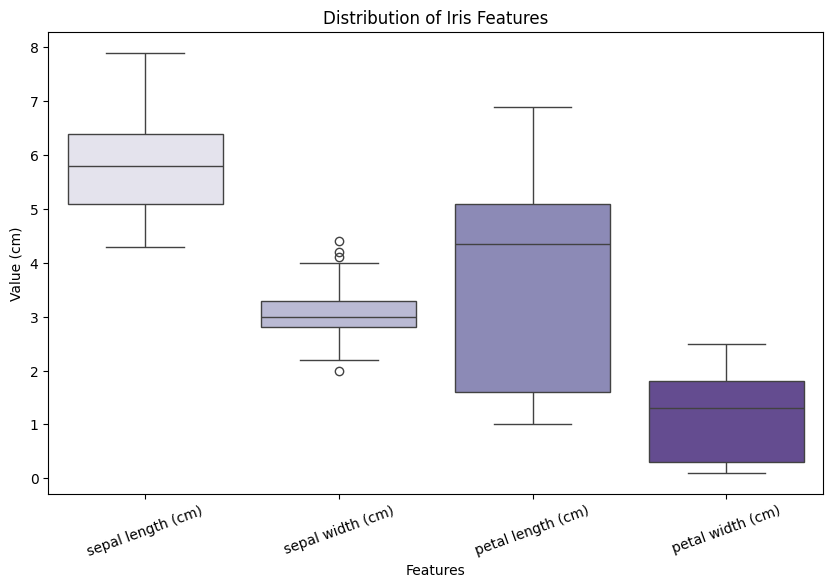

In [14]:
#feature Boxplots
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df.drop(columns=["species"]),
    palette="Purples"
)

plt.title("Distribution of Iris Features")
plt.xlabel("Features")
plt.ylabel("Value (cm)")
plt.xticks(rotation=20)
plt.show()


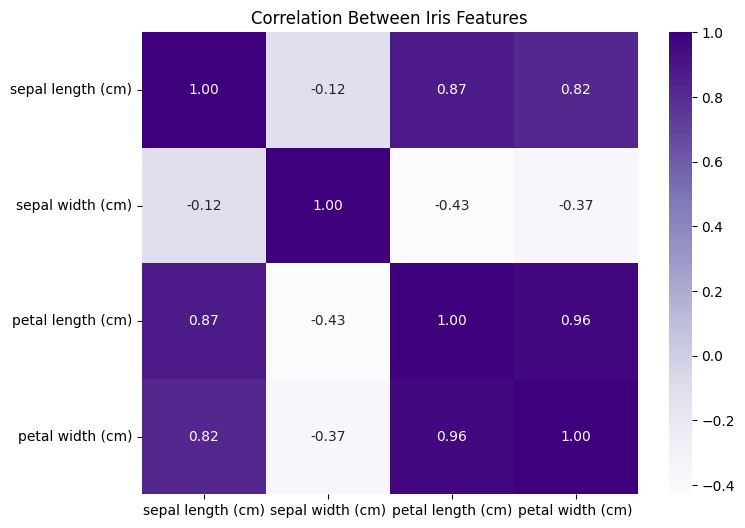

In [15]:
#correlation Heatmap
plt.figure(figsize=(8, 6))

correlation = df.drop(columns=["species"]).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="Purples",
    fmt=".2f"
)

plt.title("Correlation Between Iris Features")
plt.show()

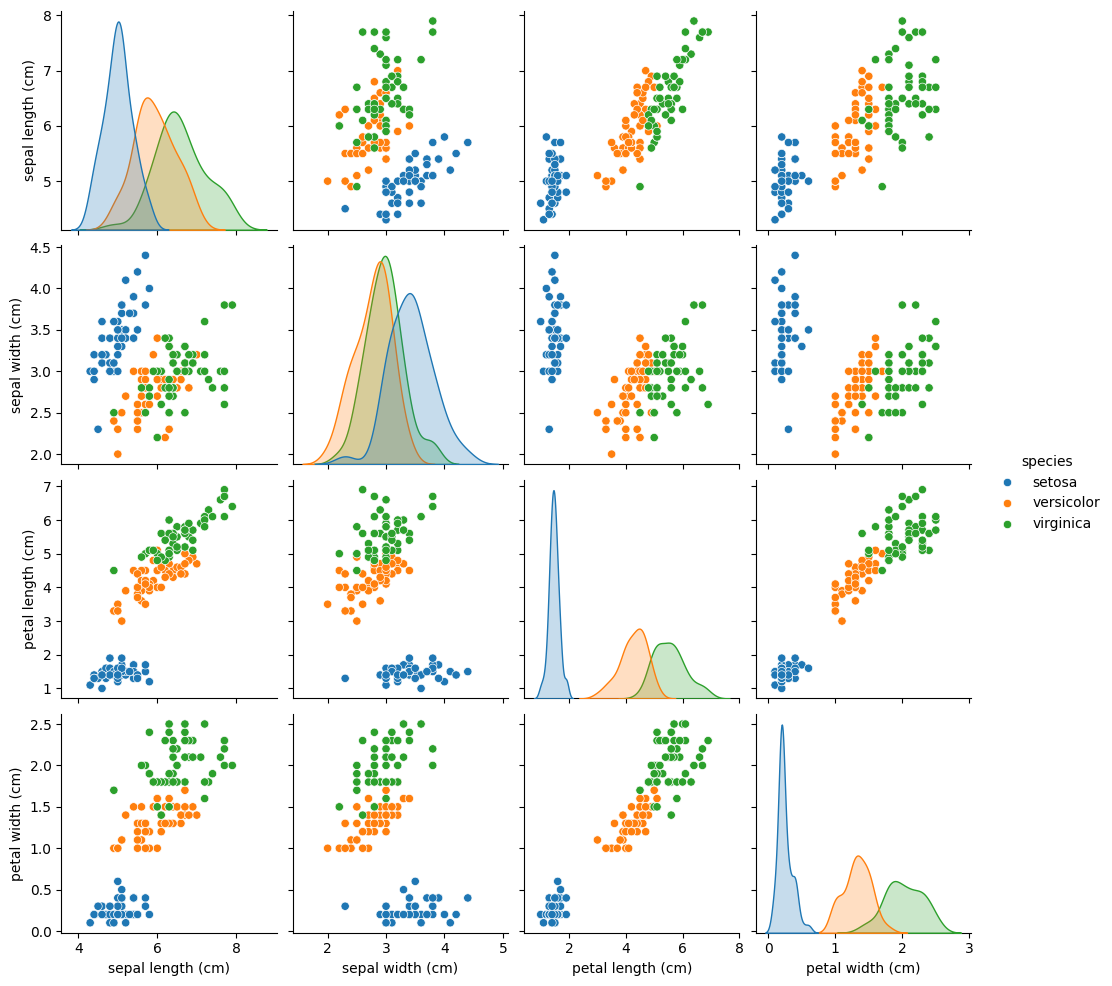

In [16]:
#Feature Pair Visualization
sns.pairplot(df, hue="species")
plt.show()

In [18]:
# First split: 80% Train+Validation, 20% Test
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Second split: 75% Train, 25% Validation

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.25,
    random_state=42,
    stratify=y_train_val
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

Training samples: 90
Validation samples: 30
Testing samples: 30


In [19]:
#Logistic Regression
logistic_model = LogisticRegression(
    max_iter=200,
    random_state=42
)

# Training
logistic_model.fit(X_train, y_train)

# Predictions
y_train_pred_lr = logistic_model.predict(X_train)
y_val_pred_lr = logistic_model.predict(X_val)
y_test_pred_lr = logistic_model.predict(X_test)

# Accuracy
lr_train_acc = accuracy_score(y_train, y_train_pred_lr)
lr_val_acc = accuracy_score(y_val, y_val_pred_lr)
lr_test_acc = accuracy_score(y_test, y_test_pred_lr)

print("Logistic Regression")
print("-" * 35)
print(f"Training Accuracy   : {lr_train_acc * 100:.2f}%")
print(f"Validation Accuracy : {lr_val_acc * 100:.2f}%")
print(f"Test Accuracy       : {lr_test_acc * 100:.2f}%")

Logistic Regression
-----------------------------------
Training Accuracy   : 97.78%
Validation Accuracy : 93.33%
Test Accuracy       : 96.67%


In [20]:
print("Logistic Regression - Test Performance")
print("-" * 45)

print(classification_report(
    y_test,
    y_test_pred_lr,
    target_names=iris.target_names
))

Logistic Regression - Test Performance
---------------------------------------------
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



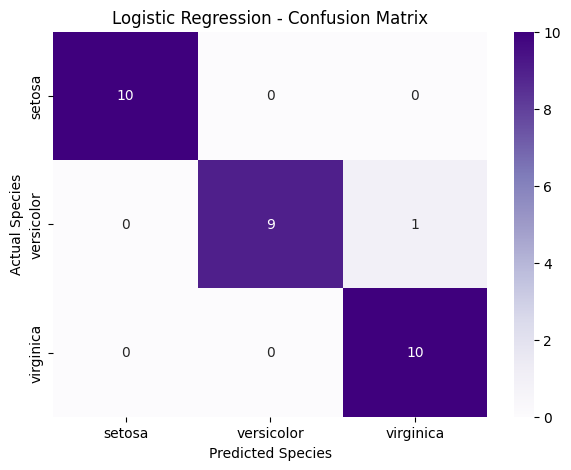

In [21]:
#confusion matrix
cm_lr = confusion_matrix(y_test, y_test_pred_lr)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.show()

In [22]:
#Decision Tree
decision_tree = DecisionTreeClassifier(
    random_state=42,
    max_depth=4
)

# Training
decision_tree.fit(X_train, y_train)

# Predictions
y_train_pred_dt = decision_tree.predict(X_train)
y_val_pred_dt = decision_tree.predict(X_val)
y_test_pred_dt = decision_tree.predict(X_test)

# Accuracy
dt_train_acc = accuracy_score(y_train, y_train_pred_dt)
dt_val_acc = accuracy_score(y_val, y_val_pred_dt)
dt_test_acc = accuracy_score(y_test, y_test_pred_dt)

print("Decision Tree")
print("-" * 35)
print(f"Training Accuracy   : {dt_train_acc * 100:.2f}%")
print(f"Validation Accuracy : {dt_val_acc * 100:.2f}%")
print(f"Test Accuracy       : {dt_test_acc * 100:.2f}%")

Decision Tree
-----------------------------------
Training Accuracy   : 100.00%
Validation Accuracy : 93.33%
Test Accuracy       : 93.33%


In [23]:
print("Decision Tree - Test Performance")
print("-" * 45)

print(classification_report(
    y_test,
    y_test_pred_dt,
    target_names=iris.target_names
))

Decision Tree - Test Performance
---------------------------------------------
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



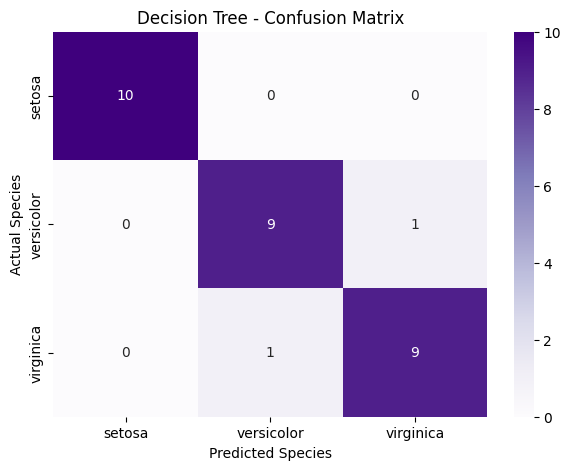

In [24]:
#confusion Matrix
cm_dt = confusion_matrix(y_test, y_test_pred_dt)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.title("Decision Tree - Confusion Matrix")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.show()

In [25]:
# comparison
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree"
    ],
    "Train Accuracy (%)": [
        lr_train_acc * 100,
        dt_train_acc * 100
    ],
    "Validation Accuracy (%)": [
        lr_val_acc * 100,
        dt_val_acc * 100
    ],
    "Test Accuracy (%)": [
        lr_test_acc * 100,
        dt_test_acc * 100
    ]
})

comparison

,Model,Train Accuracy (%),Validation Accuracy (%),Test Accuracy (%)
0,Logistic Regression,97.777778,93.333333,96.666667
1,Decision Tree,100.000000,93.333333,93.333333


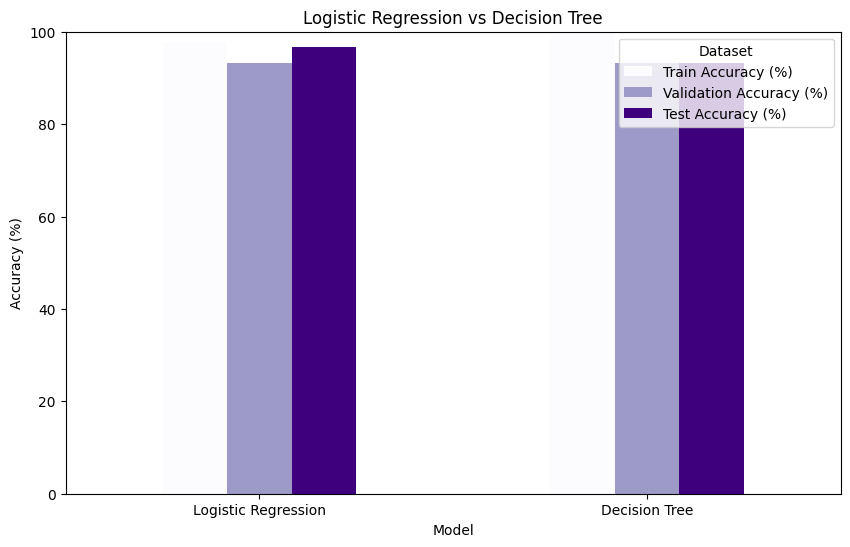

In [26]:
comparison_plot = comparison.set_index("Model")

comparison_plot.plot(
    kind="bar",
    figsize=(10, 6),
    colormap="Purples"
)

plt.title("Logistic Regression vs Decision Tree")
plt.ylabel("Accuracy (%)")
plt.xlabel("Model")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.legend(title="Dataset")
plt.show()

In [29]:
#metrics comparison

from sklearn.metrics import precision_score, recall_score, f1_score
metrics_comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "Accuracy (%)": [
        lr_test_acc * 100,
        dt_test_acc * 100
    ],
    "Precision (%)": [
        precision_score(y_test, y_test_pred_lr, average="weighted") * 100,
        precision_score(y_test, y_test_pred_dt, average="weighted") * 100
    ],
    "Recall (%)": [
        recall_score(y_test, y_test_pred_lr, average="weighted") * 100,
        recall_score(y_test, y_test_pred_dt, average="weighted") * 100
    ],
    "F1 Score (%)": [
        f1_score(y_test, y_test_pred_lr, average="weighted") * 100,
        f1_score(y_test, y_test_pred_dt, average="weighted") * 100
    ]
})

metrics_comparison.round(2)

,Model,Accuracy (%),Precision (%),Recall (%),F1 Score (%)
0,Logistic Regression,96.67,96.97,96.67,96.66
1,Decision Tree,93.33,93.33,93.33,93.33


In [35]:
# ============================================================
# IRIS FLOWER CLASSIFIER - LOGISTIC REGRESSION

# ============================================================

import numpy as np
import ipywidgets as widgets
from IPython.display import display, clear_output, HTML

# Model Name


MODEL_NAME = "Iris Flower Classifier – Logistic Regression"



# Create Dropdowns

sepal_length = widgets.Dropdown(
    options=[round(x, 1) for x in np.arange(4.0, 8.1, 0.1)],
    value=5.1,
    description="Sepal Length (cm):",
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='400px')
)

sepal_width = widgets.Dropdown(
    options=[round(x, 1) for x in np.arange(2.0, 4.5, 0.1)],
    value=3.5,
    description="Sepal Width (cm):",
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='400px')
)

petal_length = widgets.Dropdown(
    options=[round(x, 1) for x in np.arange(1.0, 7.0, 0.1)],
    value=1.4,
    description="Petal Length (cm):",
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='400px')
)

petal_width = widgets.Dropdown(
    options=[round(x, 1) for x in np.arange(0.1, 2.6, 0.1)],
    value=0.2,
    description="Petal Width (cm):",
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='400px')
)


# Predict Button


predict_button = widgets.Button(
    description="🌸 Predict Flower",
    button_style="primary",
    layout=widgets.Layout(width='200px', height='40px')
)

output = widgets.Output()


# Prediction Function


def predict_flower(button):

    with output:
        clear_output()

        # Collect user inputs
        new_flower = [[
            sepal_length.value,
            sepal_width.value,
            petal_length.value,
            petal_width.value
        ]]

        # Prediction using already-trained Logistic Regression model
        prediction = logistic_model.predict(new_flower)

        # Prediction probabilities
        probabilities = logistic_model.predict_proba(new_flower)

        # Get species name
        predicted_species = iris.target_names[prediction[0]]

        # Confidence
        confidence = max(probabilities[0]) * 100

        # Display result
        display(HTML(
            f"""
            <div style="
                border: 2px solid #7B2CBF;
                border-radius: 10px;
                padding: 15px;
                width: 370px;
                margin-top: 10px;
            ">
                <h3 style="color:#7B2CBF;">
                    🌸 Prediction Result
                </h3>

                <p><b>Model:</b> {MODEL_NAME}</p>

                <p>
                    <b>Predicted Species:</b>
                    {predicted_species.title()}
                </p>

                <p>
                    <b>Confidence:</b>
                    {confidence:.2f}%
                </p>
            </div>
            """
        ))


# Connect Button


predict_button.on_click(predict_flower)



# Display Complete Interface

display(HTML(
    f"""
    <div style="
        border: 2px solid #7B2CBF;
        border-radius: 12px;
        padding: 20px;
        width: 450px;
    ">
        <h2 style="color:#7B2CBF;">
            🌸 Iris Flower Classification
        </h2>

        <p>
            <b>Model:</b> {MODEL_NAME}
        </p>

        <p>
            Select the flower measurements below:
        </p>
    </div>
    """
))

display(
    widgets.VBox([
        sepal_length,
        sepal_width,
        petal_length,
        petal_width,
        predict_button,
        output
    ])
)

In [39]:
# ============================================================
# IRIS FLOWER CLASSIFICATION - CLI
# Single-cell standalone script
# ============================================================

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

# Load dataset
iris = load_iris()
X = iris.data
y = iris.target

# Train the Logistic Regression model
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

model = LogisticRegression(
    max_iter=200,
    random_state=42
)

model.fit(X_train, y_train)

# ------------------------------------------------------------
# CLI
# ------------------------------------------------------------

print("\n" + "=" * 50)
print("        🌸 IRIS FLOWER CLASSIFICATION 🌸")
print("=" * 50)

try:

    sepal_length = float(input("Enter Sepal Length (cm): "))
    sepal_width  = float(input("Enter Sepal Width (cm): "))
    petal_length = float(input("Enter Petal Length (cm): "))
    petal_width  = float(input("Enter Petal Width (cm): "))

    # Validate input
    if any(value <= 0 for value in [
        sepal_length,
        sepal_width,
        petal_length,
        petal_width
    ]):
        raise ValueError("All measurements must be greater than 0.")

    # New flower data
    new_flower = [[
        sepal_length,
        sepal_width,
        petal_length,
        petal_width
    ]]

    # Prediction
    prediction = model.predict(new_flower)[0]
    probabilities = model.predict_proba(new_flower)[0]

    predicted_species = iris.target_names[prediction]
    confidence = probabilities[prediction] * 100

    # Result
    print("\n" + "-" * 50)
    print("              PREDICTION RESULT")
    print("-" * 50)

    print(f"Predicted Species : {predicted_species.title()}")
    print(f"Confidence        : {confidence:.2f}%")

    print("-" * 50)

except ValueError as e:
    print("\n❌ Input Error:", e)
    print("Please enter valid numerical values.")

except Exception as e:
    print("\n❌ Unexpected Error:", e)

print("\nCLI execution completed.")


        🌸 IRIS FLOWER CLASSIFICATION 🌸
Enter Sepal Length (cm): 5.1
Enter Sepal Width (cm): 3.5
Enter Petal Length (cm): 1.4
Enter Petal Width (cm): 0.2

--------------------------------------------------
              PREDICTION RESULT
--------------------------------------------------
Predicted Species : Setosa
Confidence        : 97.84%
--------------------------------------------------

CLI execution completed.
